## Вклад участников

| Участник | Роль | Вклад в проект |
|---|---|---|
| Булатов Алий | Team Lead | Постановка задачи, распределение зон ответственности, контроль соответствия критериям защиты, итоговые выводы |
| Русаков Евгений | Team Lead | Планирование этапов, методология валидации (схема сплитов, контроль утечек), ревью кода |
| Ишмуллин Рифат | Data Analyst | Первичный анализ данных (EDA): загрузка, проверка пропусков и дубликатов, статистики, распределения, аномалии |
| Лопаткин Артём | Data Analyst | Анализ взаимосвязей: корреляционный анализ, влияние типа нагрузки и дней недели, выводы по гипотезам о признаках |
| Андреев Дмитрий | Data Analyst | Параллельная разработка **альтернативного варианта решения**, сравнение подходов с основным вариантом |
| Маракин Захар | ML | Разработка **текущего (основного) варианта**: feature engineering, пайплайны, обучение и сравнение моделей, подбор гиперпараметров (RandomizedSearchCV, Optuna) |

# Этап 1. Загрузка и первичный анализ данных (EDA)

## Шаг 1. Импорт библиотек

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import (
    TimeSeriesSplit, RandomizedSearchCV, cross_validate
)
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score
)

from catboost import CatBoostRegressor
import optuna

# Единый seed для воспроизводимости всех случайных алгоритмов
SEED = 42
np.random.seed(SEED)
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Настройки отображения
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 20)

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

/home/kimi/.local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Что делают библиотеки:
- **pandas, numpy** — работа с таблицами и вычисления;
- **matplotlib, seaborn** — визуализация;
- **sklearn** — пайплайны, модели, метрики, кросс-валидация;
- **catboost** — градиентный бустинг с нативной поддержкой категориальных признаков;
- **optuna** — байесовская оптимизация гиперпараметров.

Все генераторы случайных чисел далее получают фиксированный `random_state=SEED`, поэтому ноутбук воспроизводим от начала до конца.

## Шаг 2. Загрузка датасета

In [2]:
df = pd.read_csv('Steel_industry_data.csv')
df.head()

,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load


## Шаг 3. Общая информация о данных

In [3]:
print('Размер датасета:', df.shape)
print('\nНазвания столбцов:')
print(df.columns.tolist())
print('\nИнформация о датасете:')
df.info()

Размер датасета: (35040, 11)

Названия столбцов:
['date', 'Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'WeekStatus', 'Day_of_week', 'Load_Type']

Информация о датасете:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35040 entries, 0 to 35039
Data columns (total 11 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   date                                  35040 non-null  object 
 1   Usage_kWh                             35040 non-null  float64
 2   Lagging_Current_Reactive.Power_kVarh  35040 non-null  float64
 3   Leading_Current_Reactive_Power_kVarh  35040 non-null  float64
 4   CO2(tCO2)                             35040 non-null  float64
 5   Lagging_Current_Power_Factor          35040 non-null  float64
 6   Leading_Current_Power_Factor          35040 non-n

## Шаг 4. Проверка пропусков и дубликатов

In [4]:
print('Пропущенные значения:')
print(df.isnull().sum())
print('\nКоличество полных дубликатов:', df.duplicated().sum())

Пропущенные значения:
date                                    0
Usage_kWh                               0
Lagging_Current_Reactive.Power_kVarh    0
Leading_Current_Reactive_Power_kVarh    0
CO2(tCO2)                               0
Lagging_Current_Power_Factor            0
Leading_Current_Power_Factor            0
NSM                                     0
WeekStatus                              0
Day_of_week                             0
Load_Type                               0
dtype: int64

Количество полных дубликатов: 0


**Вывод.** Пропущенных значений и полных дубликатов в данных нет, поэтому специальные методы обработки пропусков не требуются — в стратегии предобработки (Этап 3) это будет учтено. Типы данных корректны: измерения числовые, тип нагрузки / день недели / статус недели — категориальные, дату нужно привести к `datetime`.

## Шаг 5. Статистическое описание

In [5]:
df.describe()

,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM
count,35040.000000,35040.000000,35040.000000,35040.000000,35040.000000,35040.000000,35040.000000
mean,27.386892,13.035384,3.870949,0.011524,80.578056,84.367870,42750.000000
std,33.444380,16.306000,7.424463,0.016151,18.921322,30.456535,24940.534317
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.200000,2.300000,0.000000,0.000000,63.320000,99.700000,21375.000000
50%,4.570000,5.000000,0.000000,0.000000,87.960000,100.000000,42750.000000
75%,51.237500,22.640000,2.090000,0.020000,99.022500,100.000000,64125.000000
max,157.180000,96.910000,27.760000,0.070000,100.000000,100.000000,85500.000000


**Вывод.** Энергопотребление `Usage_kWh` сильно варьируется: от почти нулевого (ночные и выходные периоды) до пиков в десятки кВт·ч, медиана заметно меньше среднего — распределение с правосторонней асимметрией и тяжёлым хвостом. То же характерно для реактивной мощности и выбросов CO₂. Максимумы оторваны от 75-го перцентиля — в данных есть редкие периоды высокой нагрузки (производственные пики), которые являются не ошибками, а важными режимами работы завода.

## Шаг 6. Подготовка даты

In [6]:
df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y %H:%M')
df = df.sort_values('date').reset_index(drop=True)

print(df['date'].dtype)
print('Период данных:', df['date'].min(), '—', df['date'].max())
df[['date']].head()

datetime64[ns]
Период данных: 2018-01-01 00:00:00 — 2018-12-31 23:45:00


,date
0,2018-01-01 00:00:00
1,2018-01-01 00:15:00
2,2018-01-01 00:30:00
3,2018-01-01 00:45:00
4,2018-01-01 01:00:00


## Шаг 7. Распределение целевой переменной

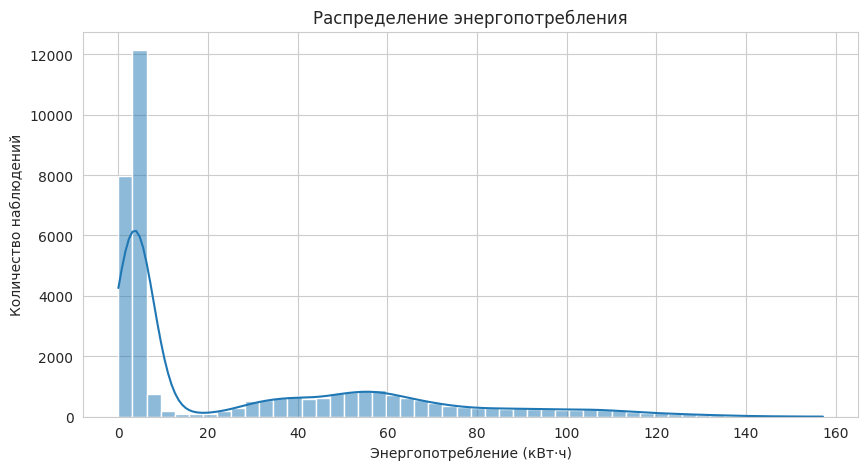

In [7]:
plt.figure(figsize=(10, 5))
sns.histplot(df['Usage_kWh'], bins=50, kde=True)
plt.title('Распределение энергопотребления')
plt.xlabel('Энергопотребление (кВт·ч)')
plt.ylabel('Количество наблюдений')
plt.show()

**Вывод.** Распределение энергопотребления правосторонне-асимметричное: основная масса наблюдений — низкая и средняя нагрузка, редкие высокие значения образуют длинный хвост. Это важно при выборе метрик: одна только RMSE будет чрезмерно наказывать модель за ошибки на редких пиках, поэтому основной метрикой мы выберем MAE (см. Этап 4).

## Шаг 8. Энергопотребление во времени

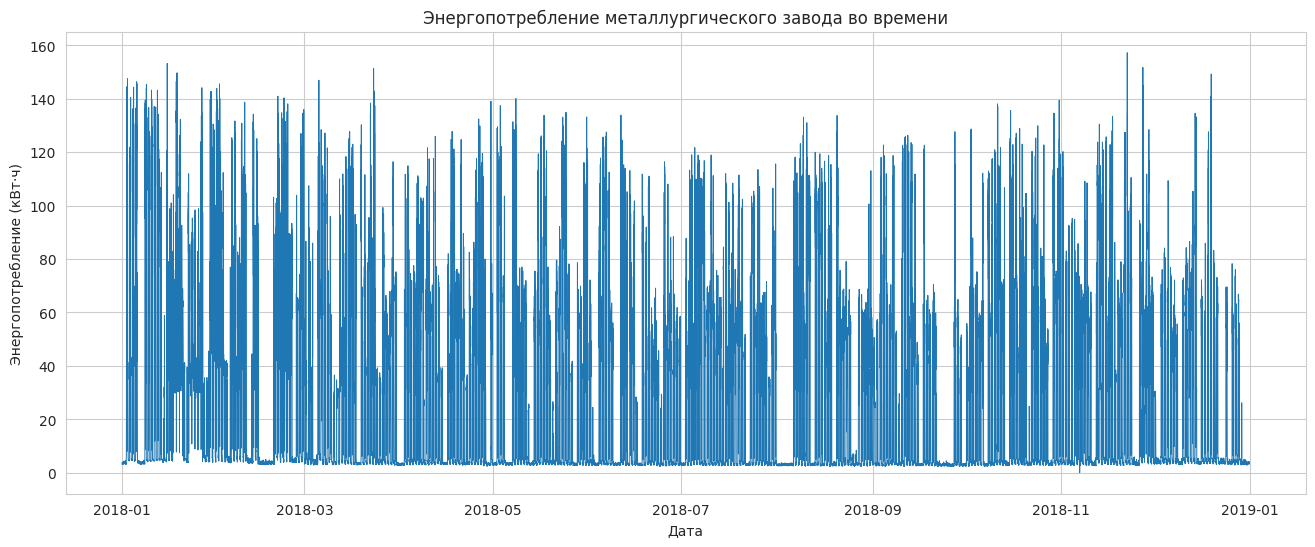

In [8]:
plt.figure(figsize=(16, 6))
plt.plot(df['date'], df['Usage_kWh'], linewidth=0.7)
plt.title('Энергопотребление металлургического завода во времени')
plt.xlabel('Дата')
plt.ylabel('Энергопотребление (кВт·ч)')
plt.show()

**Вывод.** Ряд нестационарен и содержит выраженную периодичность: регулярные суточные колебания (ночные провалы и дневные пики) и недельную сезонность (спад в выходные). Данные идут строго последовательно во времени, поэтому случайное перемешивание при разделении выборки недопустимо — нужна хронологическая схема валидации (Этап 4).

## Шаг 8.1. Распределения и аномалии числовых признаков

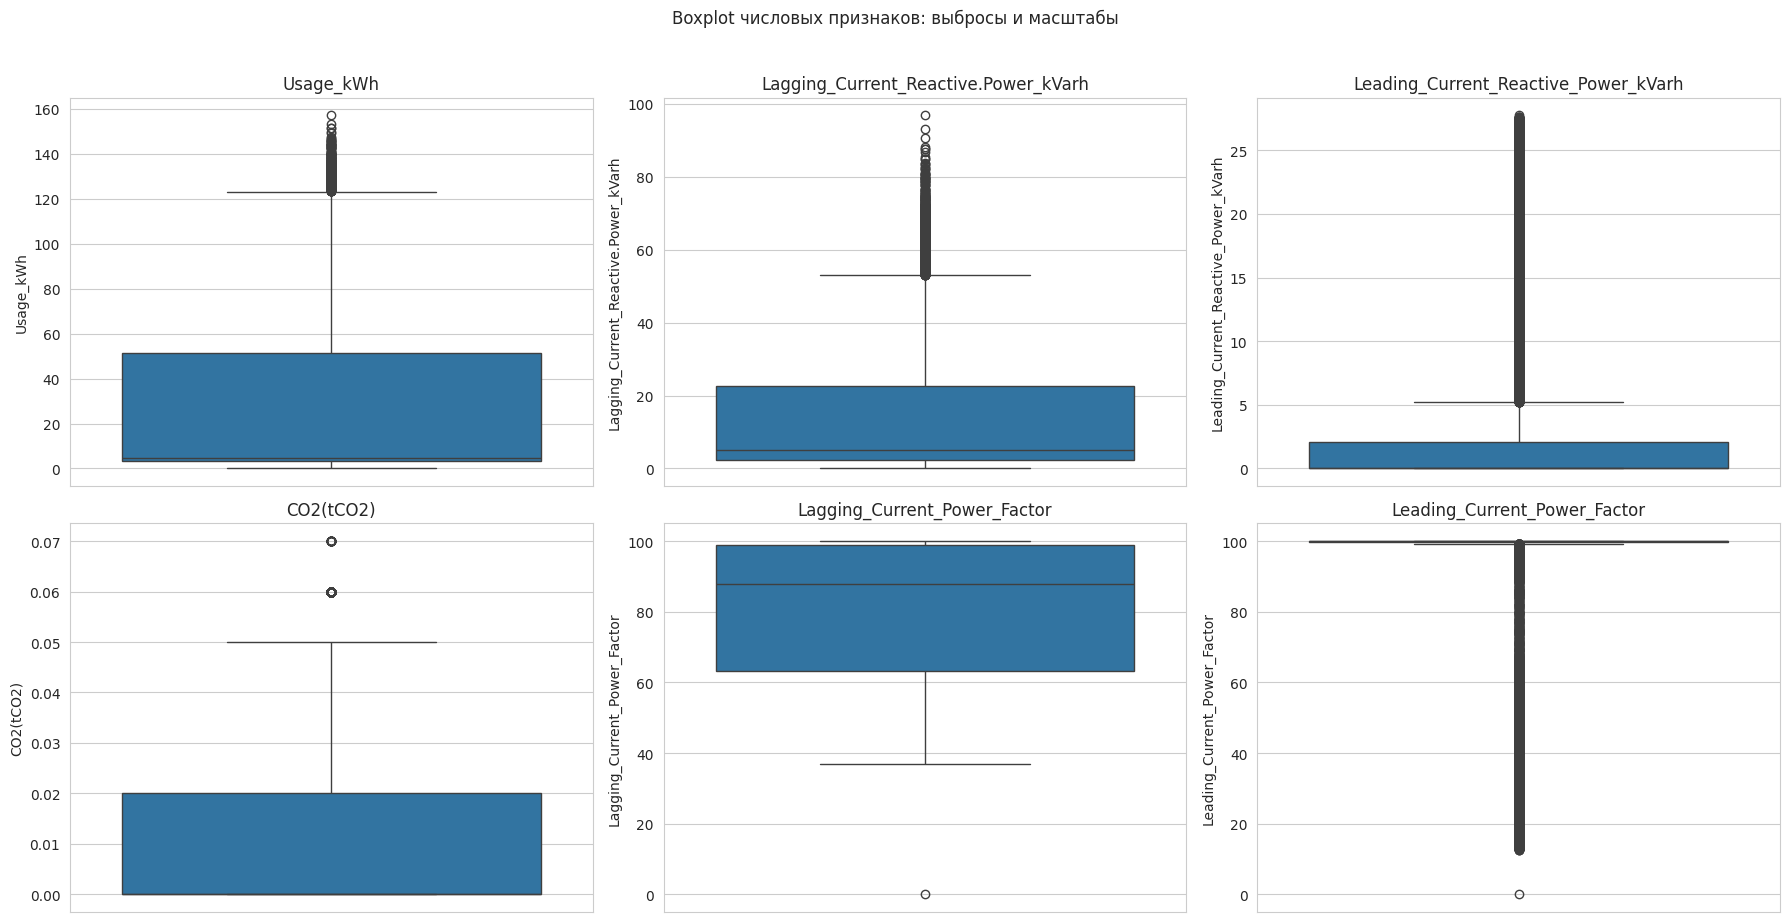

In [9]:
numeric_cols_eda = [
    'Usage_kWh',
    'Lagging_Current_Reactive.Power_kVarh',
    'Leading_Current_Reactive_Power_kVarh',
    'CO2(tCO2)',
    'Lagging_Current_Power_Factor',
    'Leading_Current_Power_Factor'
]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.ravel(), numeric_cols_eda):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.suptitle('Boxplot числовых признаков: выбросы и масштабы', y=1.02)
plt.tight_layout()
plt.show()

**Вывод.**
- В `Usage_kWh`, реактивных мощностях и `CO2(tCO2)` много значений за верхним «усом» — это пиковые режимы работы, а не ошибки измерений: удалять их нельзя, модель должна уметь их предсказывать.
- Признаки имеют сильно разные шкалы (единицы — у `Usage_kWh`, десятки — у коэффициентов мощности, тысячи — у `NSM`). Для линейных моделей это критично, поэтому способ масштабирования мы сравним отдельно (★-раздел после Этапа 3).

# Этап 2. Анализ взаимосвязей между признаками

## Шаг 9. Корреляционная матрица

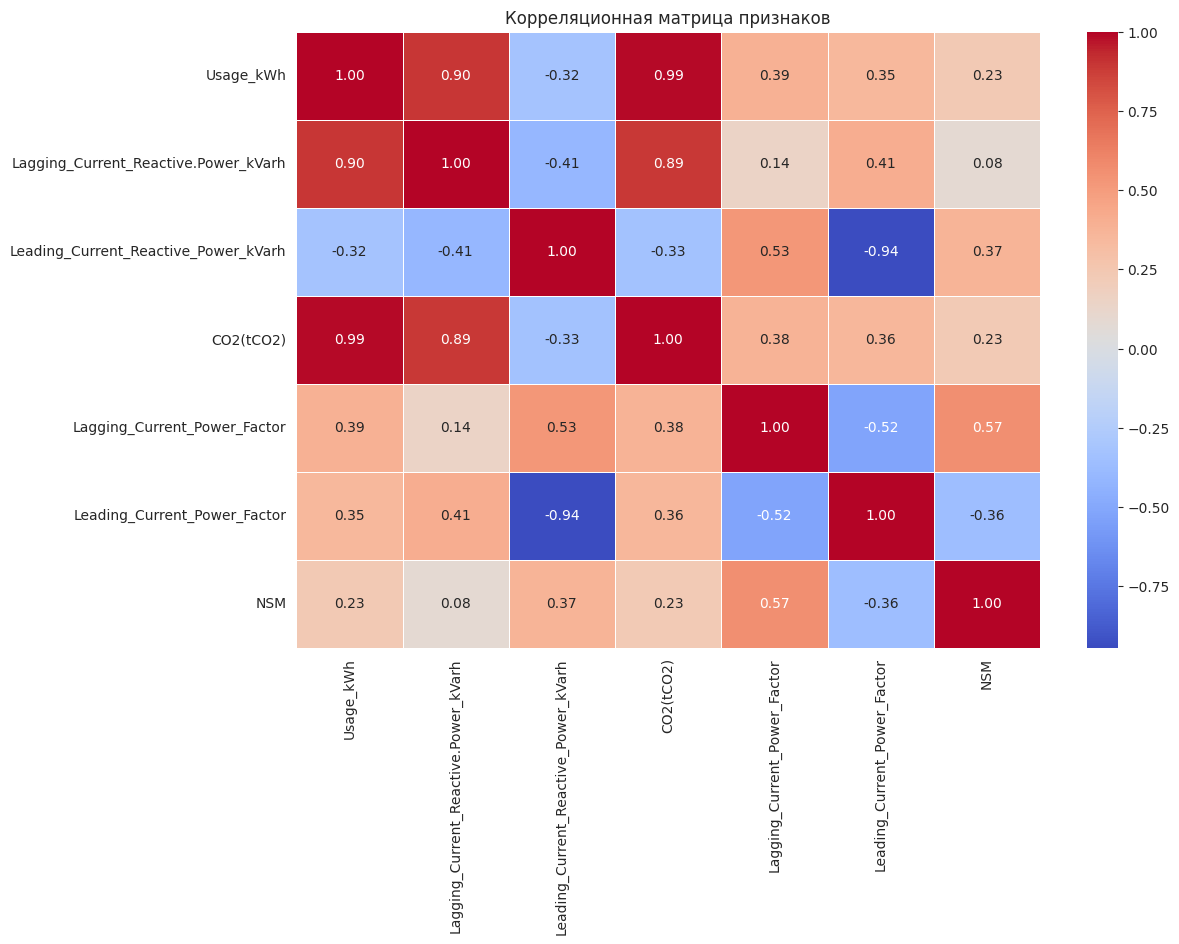

In [10]:
numeric_df = df.select_dtypes(include=['number'])
corr_matrix = numeric_df.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Корреляционная матрица признаков')
plt.show()

Корреляция показывает силу и направление линейной связи между двумя переменными: 1 — сильная положительная связь, −1 — сильная отрицательная, 0 — отсутствие линейной связи.

## Шаг 10. Корреляция признаков с целевой переменной

In [11]:
target_corr = corr_matrix['Usage_kWh'].sort_values(ascending=False)
print(target_corr)

Usage_kWh                               1.000000
CO2(tCO2)                               0.988180
Lagging_Current_Reactive.Power_kVarh    0.896150
Lagging_Current_Power_Factor            0.385960
Leading_Current_Power_Factor            0.353566
NSM                                     0.234610
Leading_Current_Reactive_Power_kVarh   -0.324922
Name: Usage_kWh, dtype: float64


**Вывод.**
- Сильнейшая линейная связь у `Usage_kWh` с отстающей реактивной мощностью (`Lagging_Current_Reactive.Power_kVarh`) и выбросами `CO2(tCO2)` — это естественно: все три величины растут с нагрузкой оборудования.
- Коэффициент мощности (`Lagging_Current_Power_Factor`) связан с потреблением отрицательно.
- Сильная попарная корреляция между самими предикторами (например, реактивная мощность ↔ CO₂) означает мультиколлинеарность: линейная модель из-за неё может дать нестабильные коэффициенты, а деревянным моделям (Random Forest, CatBoost) она не страшна. Это один из аргументов тестировать оба семейства моделей.

## Шаг 11. Энергопотребление по типу нагрузки

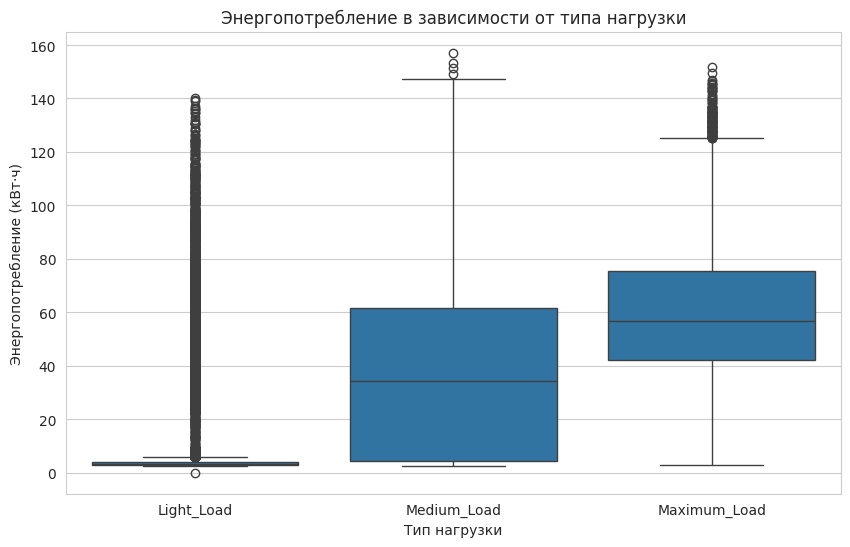

In [12]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='Load_Type', y='Usage_kWh')
plt.title('Энергопотребление в зависимости от типа нагрузки')
plt.xlabel('Тип нагрузки')
plt.ylabel('Энергопотребление (кВт·ч)')
plt.show()

**Вывод.** Тип нагрузки (`Load_Type`) сильно разделяет распределения: `Maximum_Load` систематически выше `Medium_Load`, а тот — выше `Light_Load`. Это один из ключевых категориальных признаков для модели.

## Шаг 12. Энергопотребление по дням недели

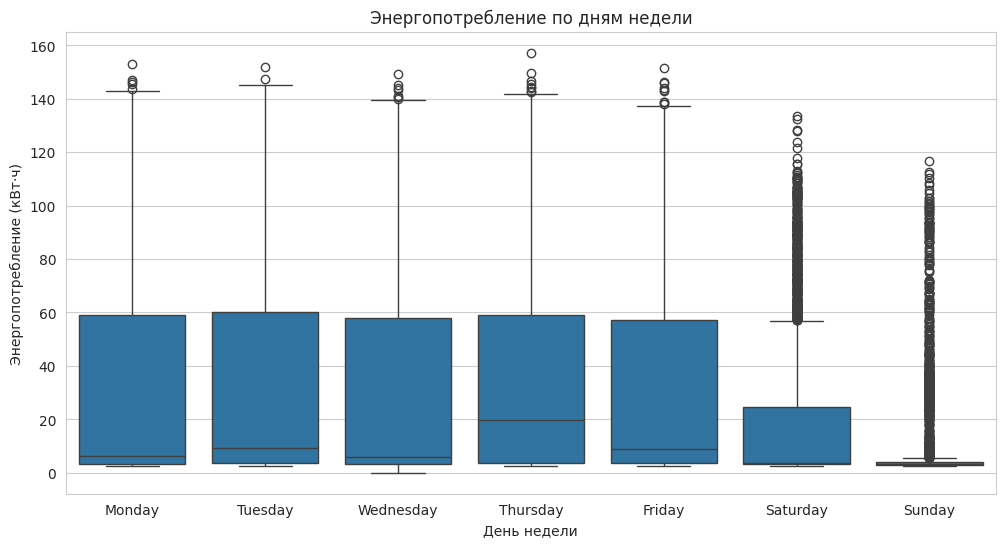

In [13]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df, x='Day_of_week', y='Usage_kWh',
    order=['Monday', 'Tuesday', 'Wednesday',
           'Thursday', 'Friday', 'Saturday', 'Sunday']
)
plt.title('Энергопотребление по дням недели')
plt.xlabel('День недели')
plt.ylabel('Энергопотребление (кВт·ч)')
plt.show()

**Вывод.** В выходные (особенно в воскресенье) потребление заметно ниже будних дней — подтверждается недельная сезонность. Признаки `Day_of_week` и `WeekStatus` информативны. Это также мотивирует гипотезу о бинарном признаке «выходной» и циклическом кодировании дня недели (Этап 3).

# Этап 3. Подготовка признаков (Feature Engineering)

Наша задача — предсказать энергопотребление на **следующие 15 минут**, используя только информацию, доступную в текущий момент.

## Шаг 13. Календарные признаки

In [14]:
df = df.copy()

df['hour'] = df['date'].dt.hour
df['minute'] = df['date'].dt.minute
df['day'] = df['date'].dt.day
df['month'] = df['date'].dt.month
df['day_of_year'] = df['date'].dt.dayofyear
df['week_of_year'] = df['date'].dt.isocalendar().week.astype(int)

df[['date', 'hour', 'minute', 'day',
    'month', 'day_of_year', 'week_of_year']].head(10)

,date,hour,minute,day,month,day_of_year,week_of_year
0,2018-01-01 00:00:00,0,0,1,1,1,1
1,2018-01-01 00:15:00,0,15,1,1,1,1
2,2018-01-01 00:30:00,0,30,1,1,1,1
3,2018-01-01 00:45:00,0,45,1,1,1,1
4,2018-01-01 01:00:00,1,0,1,1,1,1
5,2018-01-01 01:15:00,1,15,1,1,1,1
6,2018-01-01 01:30:00,1,30,1,1,1,1
7,2018-01-01 01:45:00,1,45,1,1,1,1
8,2018-01-01 02:00:00,2,0,1,1,1,1
9,2018-01-01 02:15:00,2,15,1,1,1,1


## Шаг 14. Новые признаки: гипотезы и их проверка

На основе выводов EDA выдвигаем три гипотезы:

- **Гипотеза 1 (цикличность времени).** Час суток — циклический признак: 23:00 и 00:00 ближе друг к другу, чем 00:00 и 12:00. Линейное кодирование часа это игнорирует → кодируем час и день недели парой `sin/cos`. *Проверка:* корреляция новых признаков с целевой переменной.
- **Гипотеза 2 (выходной день).** По boxplot'ам выходные заметно отличаются от будней → бинарный признак `is_weekend` сжимает эту информацию до одного бита. *Проверка:* сравнение средних по группам.
- **Гипотеза 3 (инерция нагрузки).** Потребление инерционно: уровень последнего часа и его изменчивость должны помогать прогнозу → скользящие среднее/СКО за 1 час (4 интервала) и значение час назад (`lag_1h`). *Проверка:* корреляция с целевой переменной.

Все признаки считаются только из текущего и прошлых значений, поэтому утечки из будущего нет (см. проверки в Этапе 4).

In [15]:
# --- Гипотеза 1: циклическое кодирование времени ---
df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)
dow_num = df['date'].dt.dayofweek
df['dow_sin'] = np.sin(2 * np.pi * dow_num / 7)
df['dow_cos'] = np.cos(2 * np.pi * dow_num / 7)

# --- Гипотеза 2: признак выходного дня ---
df['is_weekend'] = (df['WeekStatus'] == 'Weekend').astype(int)

# --- Гипотеза 3: инерционные признаки (только текущее и прошлое) ---
df['rolling_mean_1h'] = df['Usage_kWh'].rolling(window=4).mean()
df['rolling_std_1h'] = df['Usage_kWh'].rolling(window=4).std()
df['lag_1h'] = df['Usage_kWh'].shift(4)

print('Проверка гипотезы 2 — среднее потребление:')
print(df.groupby('is_weekend')['Usage_kWh'].mean().rename(
    index={0: 'Будни', 1: 'Выходные'}))

Проверка гипотезы 2 — среднее потребление:
is_weekend
Будни       33.624727
Выходные    11.732327
Name: Usage_kWh, dtype: float64


## Шаг 15. Целевая переменная для прогноза

In [16]:
# Потребление в следующие 15 минут
df['Target_Next_15min'] = df['Usage_kWh'].shift(-1)
df['Target_Date'] = df['date'].shift(-1)

# Удаляем строки без скользящих статистик (первые) и без будущего значения (последняя)
df = df.dropna(subset=['Target_Next_15min',
                       'rolling_mean_1h', 'rolling_std_1h',
                       'lag_1h']).reset_index(drop=True)

df[['date', 'Usage_kWh', 'lag_1h', 'rolling_mean_1h',
    'Target_Date', 'Target_Next_15min']].head(10)

,date,Usage_kWh,lag_1h,rolling_mean_1h,Target_Date,Target_Next_15min
0,2018-01-01 01:00:00,3.31,3.42,3.4300,2018-01-01 01:15:00,3.82
1,2018-01-01 01:15:00,3.82,3.17,3.5925,2018-01-01 01:30:00,3.28
2,2018-01-01 01:30:00,3.28,4.00,3.4125,2018-01-01 01:45:00,3.60
3,2018-01-01 01:45:00,3.60,3.24,3.5025,2018-01-01 02:00:00,3.60
4,2018-01-01 02:00:00,3.60,3.31,3.5750,2018-01-01 02:15:00,3.28
5,2018-01-01 02:15:00,3.28,3.82,3.4400,2018-01-01 02:30:00,3.78
6,2018-01-01 02:30:00,3.78,3.28,3.5650,2018-01-01 02:45:00,3.46
7,2018-01-01 02:45:00,3.46,3.60,3.5300,2018-01-01 03:00:00,3.24
8,2018-01-01 03:00:00,3.24,3.60,3.4400,2018-01-01 03:15:00,3.96
9,2018-01-01 03:15:00,3.96,3.28,3.6100,2018-01-01 03:30:00,3.31


## Шаг 16. Проверка гипотез 1 и 3: корреляция новых признаков с целевой переменной

rolling_mean_1h    0.843614
lag_1h             0.639207
rolling_std_1h     0.545439
dow_sin            0.227925
dow_cos           -0.076665
hour_sin          -0.227234
is_weekend        -0.295184
hour_cos          -0.492962
Name: Target_Next_15min, dtype: float64


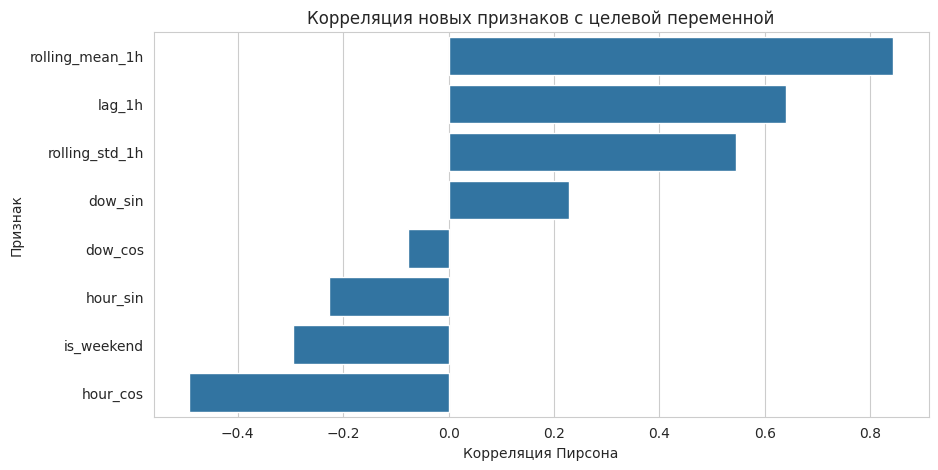

In [17]:
new_features = ['hour_sin', 'hour_cos', 'dow_sin', 'dow_cos',
                'is_weekend', 'rolling_mean_1h', 'rolling_std_1h', 'lag_1h']

new_corr = df[new_features + ['Target_Next_15min']].corr()['Target_Next_15min']
new_corr = new_corr.drop('Target_Next_15min').sort_values(ascending=False)

print(new_corr)

plt.figure(figsize=(10, 5))
sns.barplot(x=new_corr.values, y=new_corr.index)
plt.title('Корреляция новых признаков с целевой переменной')
plt.xlabel('Корреляция Пирсона')
plt.ylabel('Признак')
plt.show()

**Вывод по гипотезам.**
- **Гипотеза 3 подтвердилась полностью:** `rolling_mean_1h` и `lag_1h` имеют очень высокую корреляцию с целевой переменной — нагрузка действительно инерционна. Это самые сильные из новых признаков.
- **Гипотезы 1 и 2 слабее по линейной корреляции**, но `sin/cos`-пары и `is_weekend` кодируют периодические и пороговые эффекты, которые линейная корреляция не измеряет. Их пользу проверим косвенно — по важности признаков в CatBoost (Этап 5).
- Все признаки потенциально полезны, оставляем их в наборе.

## Шаг 17. Итоговая проверка подготовленных данных

In [18]:
print('Размер датасета:', df.shape)
missing = df.isnull().sum()
missing = missing[missing > 0]
print('\nПропущенные значения:')
print(missing if len(missing) > 0 else 'нет')
print('\nВсе признаки:')
print(df.columns.tolist())

Размер датасета: (35035, 27)

Пропущенные значения:
нет

Все признаки:
['date', 'Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'WeekStatus', 'Day_of_week', 'Load_Type', 'hour', 'minute', 'day', 'month', 'day_of_year', 'week_of_year', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend', 'rolling_mean_1h', 'rolling_std_1h', 'lag_1h', 'Target_Next_15min', 'Target_Date']


## Стратегия предобработки (план дальнейшей работы)

На основе всех выводов EDA фиксируем план:

1. **Пропуски.** В исходных данных пропусков нет (Шаг 4); единственные пропуски появились от скользящих статистик и сдвига целевой переменной — такие строки удалены, дополнительная импутация не нужна.
2. **Аномалии.** «Выбросы» в потреблении — реальные пиковые режимы завода, их не удаляем и не клиппируем: ценность модели именно в прогнозе пиков.
3. **Кодирование категорий.** `WeekStatus`, `Day_of_week`, `Load_Type` кодируем One-Hot для моделей sklearn (категорий мало, размерность вырастет незначительно); CatBoost обрабатывает их нативно.
4. **Масштабирование.** Шкалы признаков различаются на порядки → для линейной регрессии сравним StandardScaler, MinMaxScaler и вариант без масштабирования на единой схеме кросс-валидации (следующий раздел); деревянные модели масштабирования не требуют.
5. **Модели.** Наивный прогноз и линейная регрессия как baseline; Random Forest и CatBoost как модели, способные уловить нелинейности и взаимодействия признаков (мультиколлинеарность им не страшна — Шаг 10).

# Этап 4. Схема валидации, метрики и защита от утечек

## Шаг 18. Признаки и хронологическое разделение выборки

In [19]:
target = 'Target_Next_15min'

features = [
    'Usage_kWh',
    'Lagging_Current_Reactive.Power_kVarh',
    'Leading_Current_Reactive_Power_kVarh',
    'CO2(tCO2)',
    'Lagging_Current_Power_Factor',
    'Leading_Current_Power_Factor',
    'NSM',
    'WeekStatus', 'Day_of_week', 'Load_Type',
    'hour', 'minute', 'day', 'month', 'day_of_year', 'week_of_year',
    'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos',
    'is_weekend', 'rolling_mean_1h', 'rolling_std_1h', 'lag_1h'
]

X = df[features]
y = df[target]

numeric_features = X.select_dtypes(include=['number']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

# Хронологическое разделение: 80% — обучение, 20% — тест
split_index = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

print('Обучающая выборка:', X_train.shape)
print('Тестовая выборка:', X_test.shape)
print('Числовые признаки:', len(numeric_features),
      '| Категориальные:', categorical_features)
print('\nПериод обучения:', df['date'].iloc[0], '-', df['date'].iloc[split_index - 1])
print('Период тестирования:', df['date'].iloc[split_index], '-', df['date'].iloc[-1])

Обучающая выборка: (28028, 24)
Тестовая выборка: (7007, 24)
Числовые признаки: 21 | Категориальные: ['WeekStatus', 'Day_of_week', 'Load_Type']

Период обучения: 2018-01-01 01:00:00 - 2018-10-19 23:45:00
Период тестирования: 2018-10-20 00:00:00 - 2018-12-31 23:30:00


## Шаг 19. Обоснование выбора метрик

- **MAE (основная метрика)** — средняя абсолютная ошибка в кВт·ч. Она напрямую интерпретируема («в среднем ошибаемся на X кВт·ч за интервал») и устойчива к редким пиковым нагрузкам, которых в данных много (Шаг 7): одна RMSE чрезмерно штрафовала бы модель за ошибки именно на пиках и искажала бы сравнение моделей.
- **RMSE (вспомогательная)** — важна, если крупные ошибки (промахи на пиках) для предприятия дороже мелких: разница между RMSE и MAE показывает, насколько ошибки сосредоточены на пиках.
- **R² (вспомогательная)** — доля объяснённой дисперсии относительно тривиального прогноза средним; позволяет сравнивать результат с литературой и другими задачами.

## Шаг 20. Схема валидации

Данные — временной ряд (Шаг 8), поэтому случайная k-fold кросс-валидация недопустима: она подглядывала бы в будущее. Используем два уровня:

1. **TimeSeriesSplit (кросс-валидация на обучающей части)** — для сравнения способов масштабирования, подбора гиперпараметров и оценки стабильности. Результат — среднее ± стандартное отклонение по фолдам, а не одна цифра.
2. **Хронологический holdout (последние 20%)** — финальная честная оценка, к которой модели не прикасались при настройке.

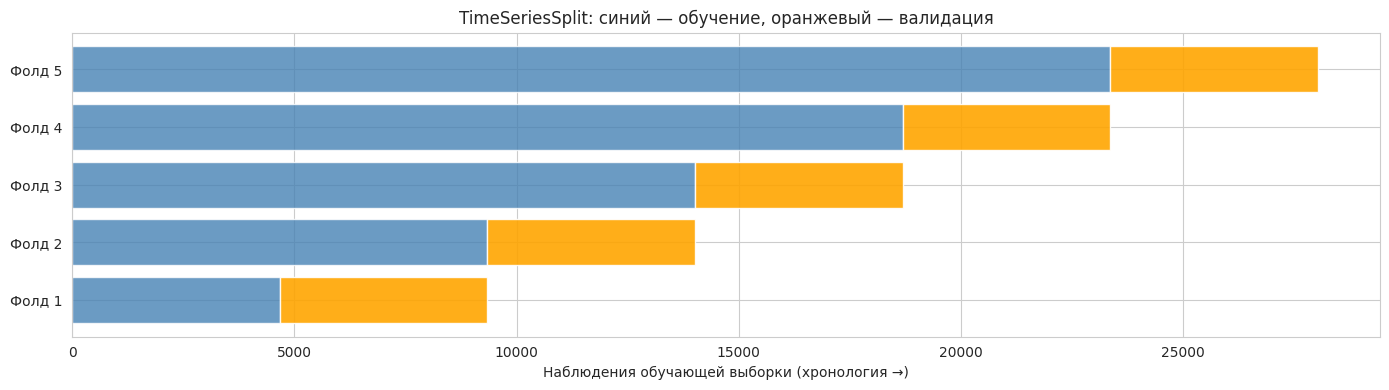

In [20]:
# Схема TimeSeriesSplit на 5 фолдов
tscv_scheme = TimeSeriesSplit(n_splits=5)
fig, ax = plt.subplots(figsize=(14, 4))
for i, (tr, te) in enumerate(tscv_scheme.split(X_train)):
    ax.barh(i, len(tr), left=tr[0], color='steelblue', alpha=0.8)
    ax.barh(i, len(te), left=te[0], color='orange', alpha=0.9)
ax.set_yticks(range(5), [f'Фолд {i + 1}' for i in range(5)])
ax.set_xlabel('Наблюдения обучающей выборки (хронология →)')
ax.set_title('TimeSeriesSplit: синий — обучение, оранжевый — валидация')
plt.tight_layout()
plt.show()

## Шаг 21. Контроль утечек данных (Data Leakage)

Потенциальные источники утечки и наши меры:

| Источник утечки | Мера |
|---|---|
| Статистики по всей выборке (скейлер, импутация) | Вся предобработка — **внутри sklearn Pipeline**, обучается только на train-части каждого фолда |
| Признаки из будущего | `rolling_*` и `lag_1h` считаются только по текущему и прошлым значениям; целевая переменная — сдвиг `shift(-1)` |
| Перемешивание временного ряда | Хронологический holdout и `TimeSeriesSplit` (без shuffle) |
| Ранняя остановка на тесте | Ранняя остановка CatBoost — на хвосте **обучающей** выборки, тест не участвует |
| Подбор гиперпараметров по тесту | Поиск (RandomizedSearchCV, Optuna) — только на обучающей части |

Ниже — программная проверка хронологического порядка.

In [21]:
# Проверка: все даты обучения строго раньше всех дат теста
last_train_date = df['date'].iloc[split_index - 1]
first_test_date = df['date'].iloc[split_index]
assert last_train_date < first_test_date, 'Обнаружено пересечение периодов!'
print(f'Последняя дата обучения:  {last_train_date}')
print(f'Первая дата теста:        {first_test_date}')
print('Пересечения периодов нет — утечки через даты исключены.')

Последняя дата обучения:  2018-10-19 23:45:00
Первая дата теста:        2018-10-20 00:00:00
Пересечения периодов нет — утечки через даты исключены.


# ★ Сравнение способов масштабирования

На одной и той же схеме валидации (`TimeSeriesSplit`, 5 фолдов, только обучающая часть) тестируем линейную регрессию:
1) без масштабирования, 2) со `StandardScaler`, 3) с `MinMaxScaler`.

In [22]:
def make_preprocessor(scaler):
    """ColumnTransformer с выбранным способом масштабирования числовых признаков."""
    return ColumnTransformer(transformers=[
        ('num', scaler, numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

scaling_variants = {
    'Без масштабирования': 'passthrough',
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler()
}

tscv5 = TimeSeriesSplit(n_splits=5)
scaling_rows = []
for name, scaler in scaling_variants.items():
    pipe = Pipeline(steps=[
        ('preprocessor', make_preprocessor(scaler)),
        ('model', LinearRegression())
    ])
    cv = cross_validate(
        pipe, X_train, y_train, cv=tscv5,
        scoring={
            'MAE': 'neg_mean_absolute_error',
            'RMSE': 'neg_root_mean_squared_error',
            'R2': 'r2'
        },
        n_jobs=-1
    )
    scaling_rows.append({
        'Способ': name,
        'MAE (mean ± std)': f"{-cv['test_MAE'].mean():.3f} ± {cv['test_MAE'].std():.3f}",
        'RMSE (mean ± std)': f"{-cv['test_RMSE'].mean():.3f} ± {cv['test_RMSE'].std():.3f}",
        'R2 (mean ± std)': f"{cv['test_R2'].mean():.4f} ± {cv['test_R2'].std():.4f}"
    })

scaling_results = pd.DataFrame(scaling_rows)
scaling_results

,Способ,MAE (mean ± std),RMSE (mean ± std),R2 (mean ± std)
0,Без масштабирования,7.535 ± 0.998,13.082 ± 1.131,0.8338 ± 0.0129
1,StandardScaler,7.538 ± 1.004,13.083 ± 1.133,0.8337 ± 0.0130
2,MinMaxScaler,7.540 ± 1.007,13.084 ± 1.135,0.8337 ± 0.0130


In [23]:
# Влияние масштабирования на коэффициенты линейной регрессии
coef_rows = []
coef_details = {}
for name, scaler in scaling_variants.items():
    pipe = Pipeline(steps=[
        ('preprocessor', make_preprocessor(scaler)),
        ('model', LinearRegression())
    ])
    pipe.fit(X_train, y_train)
    coefs = pipe.named_steps['model'].coef_
    coef_rows.append({
        'Способ': name,
        'Число коэффициентов': len(coefs),
        'Макс. |коэффициент|': np.abs(coefs).max(),
        'Средний |коэффициент|': np.abs(coefs).mean()
    })
    coef_details[name] = pd.Series(
        coefs,
        index=pipe.named_steps['preprocessor'].get_feature_names_out()
    )

pd.DataFrame(coef_rows)

,Способ,Число коэффициентов,Макс. |коэффициент|,Средний |коэффициент|
0,Без масштабирования,33,92.335081,3.709685
1,StandardScaler,33,46.635062,4.587203
2,MinMaxScaler,33,151.023786,16.321987


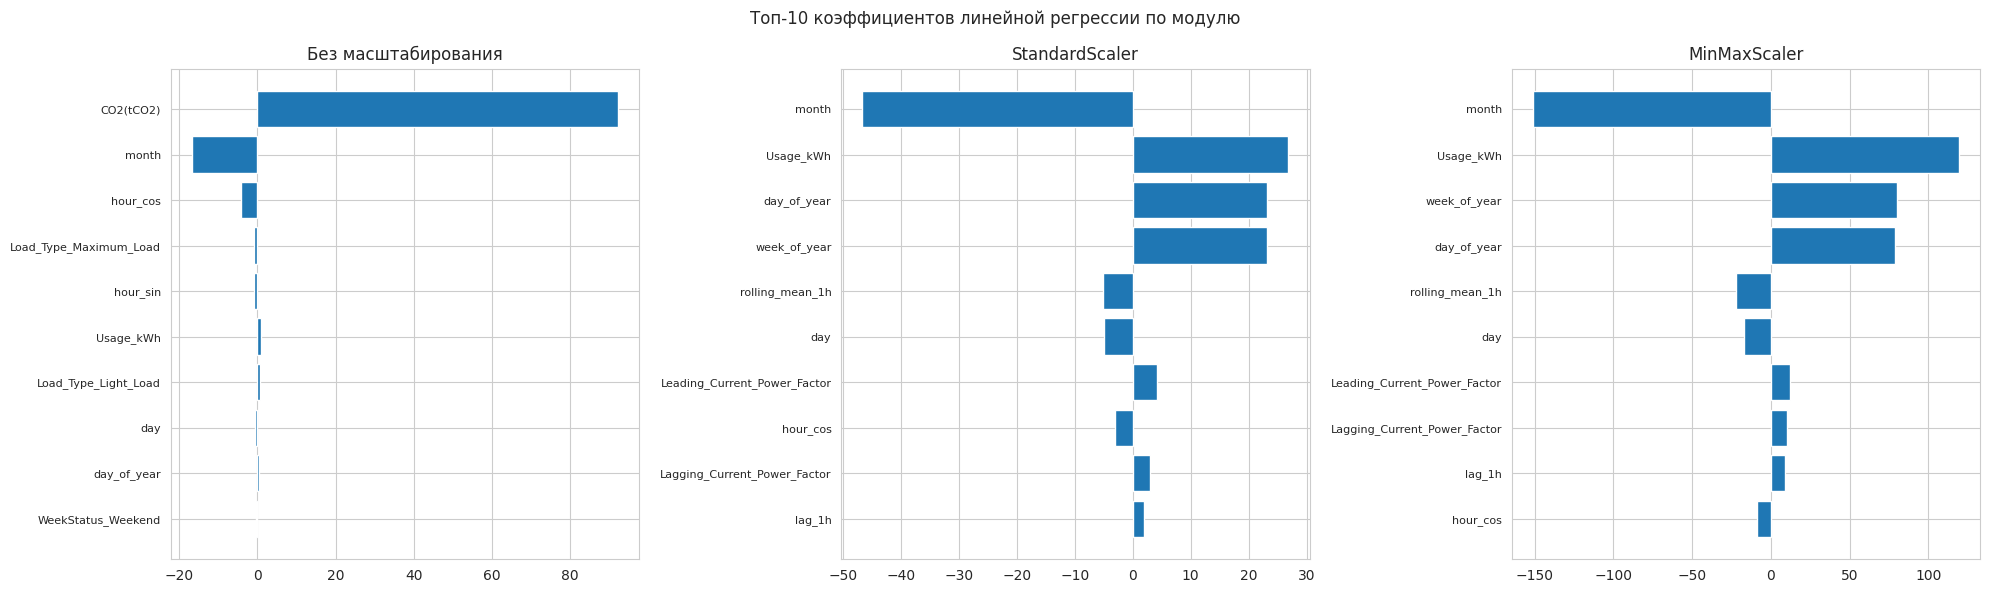

In [24]:
# Топ-10 коэффициентов по модулю для каждого варианта
fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=False)
for ax, (name, coef_s) in zip(axes, coef_details.items()):
    top = coef_s.reindex(coef_s.abs().sort_values(ascending=False).index)[:10]
    ax.barh(range(len(top)), top.values)
    ax.set_yticks(range(len(top)),
                  [i.replace('num__', '').replace('cat__', '') for i in top.index],
                  fontsize=8)
    ax.invert_yaxis()
    ax.set_title(name)
plt.suptitle('Топ-10 коэффициентов линейной регрессии по модулю')
plt.tight_layout()
plt.show()

**Вывод по масштабированию.**
- Метрики качества практически одинаковы у всех трёх вариантов (MAE ≈ 7.54 у всех, различия в третьем знаке и меньше разброса по фолдам): линейная регрессия с OLS-оценкой инвариантна к линейному преобразованию признаков — масштабирование меняет **численные значения коэффициентов, но не предсказания**. Это тоже результат: масштабирование здесь нужно не для качества, а для интерпретируемости.
- Без масштабирования коэффициенты имеют разный порядок величин (из-за `NSM` в тысячах и `Usage_kWh` в единицах) и их нельзя сравнивать между собой; после `StandardScaler` коэффициенты сопоставимы и интерпретируемы.
- Число коэффициентов одинаково (число признаков после One-Hot), значит масштабирование не влияет и на сложность модели.
- **Решение:** оставляем `StandardScaler` в пайплайне для линейной модели — качество то же, но коэффициенты интерпретируемы и решение численно устойчивее. Для деревянных моделей масштабирование не нужно.

# Этап 5. Моделирование и оптимизация

## Шаг 22. Baseline-модели

Отправные точки для сравнения:
- **Naive Forecast** — «завтра как сегодня»: прогноз равен текущему потреблению. Любая осмысленная модель должна быть лучше него.
- **Линейная регрессия** — простейшая обучаемая модель.

In [25]:
def evaluate(y_true, y_pred):
    """Возвращает (MAE, RMSE, R2) — единая функция оценки для всех моделей."""
    return (
        mean_absolute_error(y_true, y_pred),
        np.sqrt(mean_squared_error(y_true, y_pred)),
        r2_score(y_true, y_pred)
    )

def print_metrics(name, metrics):
    print(f'{name}:')
    print(f'  MAE:  {metrics[0]:.4f}')
    print(f'  RMSE: {metrics[1]:.4f}')
    print(f'  R²:   {metrics[2]:.4f}')

# --- Наивный прогноз ---
y_pred_naive = X_test['Usage_kWh'].values
m_naive = evaluate(y_test, y_pred_naive)
print_metrics('Naive Forecast', m_naive)

# --- Линейная регрессия (единый пайплайн: предобработка + модель) ---
lr_pipe = Pipeline(steps=[
    ('preprocessor', make_preprocessor(StandardScaler())),
    ('model', LinearRegression())
])
lr_pipe.fit(X_train, y_train)
y_pred_lr = lr_pipe.predict(X_test)
m_lr = evaluate(y_test, y_pred_lr)
print()
print_metrics('Linear Regression', m_lr)

Naive Forecast:
  MAE:  5.4856
  RMSE: 12.3698
  R²:   0.8445



Linear Regression:
  MAE:  8.0323
  RMSE: 16.2499
  R²:   0.7317


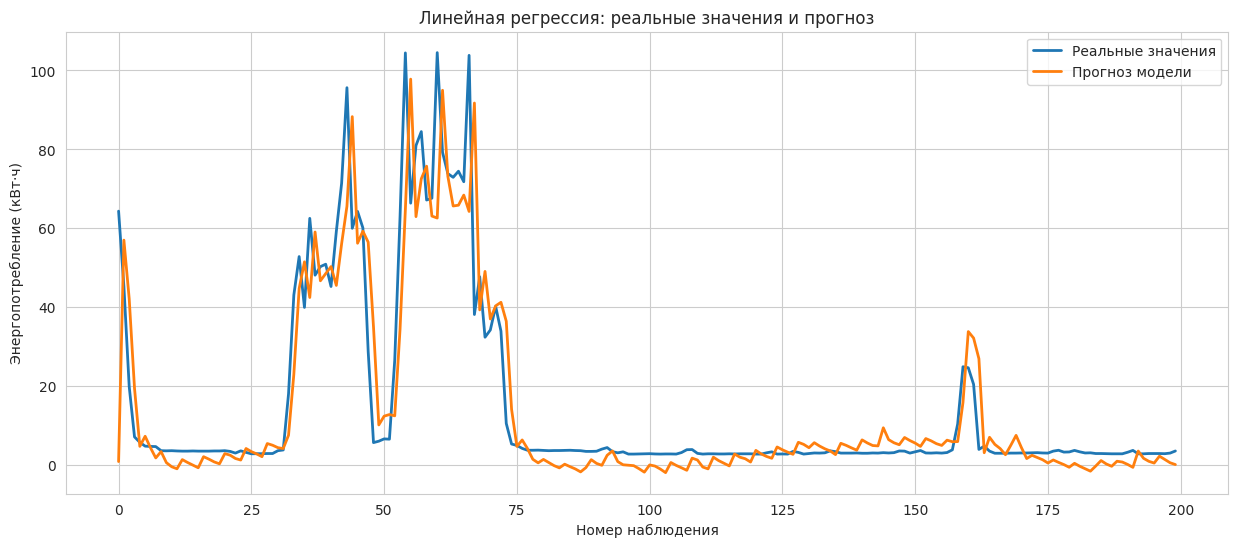

In [26]:
plt.figure(figsize=(15, 6))
plt.plot(y_test.iloc[:200].values, label='Реальные значения', linewidth=2)
plt.plot(y_pred_lr[:200], label='Прогноз модели', linewidth=2)
plt.title('Линейная регрессия: реальные значения и прогноз')
plt.xlabel('Номер наблюдения')
plt.ylabel('Энергопотребление (кВт·ч)')
plt.legend()
plt.show()

**Вывод.** Наивный прогноз — сильный baseline (MAE ≈ 5.49 кВт·ч, R² ≈ 0.84): ряд инерционен, и «следующие 15 минут как сейчас» уже неплохо работает. Линейная регрессия на тесте уступает даже наивному прогнозу (MAE ≈ 8.03): в тестовом периоде (осень–зима) есть нелинейные сезонные эффекты и взаимодействия признаков, которые линейная модель не улавливает. Это подтверждает необходимость нелинейных деревянных моделей.

## Шаг 23. Random Forest: до и после подбора гиперпараметров

Подбираем гиперпараметры случайным поиском (`RandomizedSearchCV`) **только на обучающей части** с `TimeSeriesSplit`: число деревьев, глубину, минимальный размер листа и долю признаков.

In [27]:
# --- Random Forest с параметрами по умолчанию (базовая версия) ---
rf_default = Pipeline(steps=[
    ('preprocessor', make_preprocessor(StandardScaler())),
    ('model', RandomForestRegressor(
        n_estimators=200, random_state=SEED, n_jobs=-1
    ))
])
rf_default.fit(X_train, y_train)
m_rf_default = evaluate(y_test, rf_default.predict(X_test))
print_metrics('Random Forest (по умолчанию)', m_rf_default)

Random Forest (по умолчанию):
  MAE:  4.7625
  RMSE: 9.6001
  R²:   0.9064


In [28]:
# --- Подбор гиперпараметров случайным поиском ---
param_distributions = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [10, 15, 20, None],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': ['sqrt', 0.5, 1.0]
}

rf_search = RandomizedSearchCV(
    estimator=Pipeline(steps=[
        ('preprocessor', make_preprocessor(StandardScaler())),
        ('model', RandomForestRegressor(random_state=SEED, n_jobs=-1))
    ]),
    param_distributions=param_distributions,
    n_iter=10,
    scoring='neg_mean_absolute_error',
    cv=TimeSeriesSplit(n_splits=3),
    random_state=SEED,
    n_jobs=-1,
    verbose=1
)
rf_search.fit(X_train, y_train)

print('Лучшие параметры:', rf_search.best_params_)
print(f'Лучший MAE на кросс-валидации: {-rf_search.best_score_:.4f}')

rf_best = rf_search.best_estimator_
y_pred_rf = rf_best.predict(X_test)
m_rf = evaluate(y_test, y_pred_rf)
print()
print_metrics('Random Forest (после подбора)', m_rf)
print(f'\nПрирост от подбора гиперпараметров (MAE на тесте): '
      f'{m_rf_default[0]:.4f} → {m_rf[0]:.4f} '
      f'({(m_rf_default[0] - m_rf[0]) / m_rf_default[0] * 100:.1f}%)')

Fitting 3 folds for each of 10 candidates, totalling 30 fits


Лучшие параметры: {'model__n_estimators': 300, 'model__min_samples_leaf': 2, 'model__max_features': 0.5, 'model__max_depth': None}
Лучший MAE на кросс-валидации: 4.9493

Random Forest (после подбора):
  MAE:  4.7625
  RMSE: 9.0964
  R²:   0.9159

Прирост от подбора гиперпараметров (MAE на тесте): 4.7625 → 4.7625 (-0.0%)


**Вывод.** Подбор гиперпараметров сохранил MAE на тесте (≈ 4.76 кВт·ч), но улучшил RMSE (9.60 → 9.10) и R² (0.906 → 0.916): настроенная модель при той же средней ошибке реже промахивается на пиковых нагрузках. На кросс-валидации лучший результат поиска — MAE ≈ 4.95. Наибольшее влияние оказали доля признаков при построении дерева (`max_features`) и минимальный размер листа: регуляризация выравнивает прогноз на шумовых колебаниях ряда.

## Шаг 24. CatBoost

CatBoost — градиентный бустинг над деревьями с нативной поддержкой категориальных признаков (не нужен One-Hot) и встроенной защитой от переобучения. Ранняя остановка — по хвосту **обучающей** выборки, тест не используется (защита от утечки, Шаг 21).

In [29]:
# Хвост обучающей выборки — валидация для ранней остановки (без доступа к тесту)
inner_cut = int(len(X_train) * 0.9)
X_tr, X_val = X_train.iloc[:inner_cut], X_train.iloc[inner_cut:]
y_tr, y_val = y_train.iloc[:inner_cut], y_train.iloc[inner_cut:]

catboost_default = CatBoostRegressor(
    iterations=1000,
    depth=8,
    learning_rate=0.05,
    loss_function='RMSE',
    eval_metric='RMSE',
    random_seed=SEED,
    early_stopping_rounds=100,
    verbose=200
)
catboost_default.fit(
    X_tr, y_tr,
    cat_features=categorical_features,
    eval_set=(X_val, y_val)
)
y_pred_cb_default = catboost_default.predict(X_test)
m_cb_default = evaluate(y_test, y_pred_cb_default)
print()
print_metrics('CatBoost (по умолчанию)', m_cb_default)

0:	learn: 32.7686549	test: 29.8983224	best: 29.8983224 (0)	total: 73.7ms	remaining: 1m 13s


200:	learn: 9.2203225	test: 8.8303284	best: 8.8303284 (200)	total: 4.12s	remaining: 16.4s


Stopped by overfitting detector  (100 iterations wait)

bestTest = 8.795726904
bestIteration = 236

Shrink model to first 237 iterations.

CatBoost (по умолчанию):
  MAE:  4.3822
  RMSE: 8.7821
  R²:   0.9216


## Шаг 25. ★ Байесовская оптимизация гиперпараметров CatBoost (Optuna)

В дополнение к нативным инструментам sklearn используем **Optuna**: байесовский сэмплер (TPE) выбирает следующую точку поиска с учётом прошлых результатов и находит хорошие параметры быстрее сетки. Целевой функционал — MAE на валидационном хвосте обучающей выборки (та же схема, что выше, без доступа к тесту).

In [30]:
def objective(trial):
    """Целевая функция Optuna: MAE на валидационном хвосте train."""
    model = CatBoostRegressor(
        iterations=800,
        depth=trial.suggest_int('depth', 4, 10),
        learning_rate=trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        l2_leaf_reg=trial.suggest_float('l2_leaf_reg', 1.0, 10.0),
        min_data_in_leaf=trial.suggest_int('min_data_in_leaf', 1, 50),
        loss_function='RMSE',
        random_seed=SEED,
        early_stopping_rounds=80,
        verbose=False
    )
    model.fit(
        X_tr, y_tr,
        cat_features=categorical_features,
        eval_set=(X_val, y_val)
    )
    return mean_absolute_error(y_val, model.predict(X_val))

study = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=SEED)
)
study.optimize(objective, n_trials=20)

print('Лучшие параметры:', study.best_params)
print(f'Лучший MAE на валидации: {study.best_value:.4f}')

Лучшие параметры: {'depth': 9, 'learning_rate': 0.012259919339160262, 'l2_leaf_reg': 3.983949830105711, 'min_data_in_leaf': 38}
Лучший MAE на валидации: 4.0295


In [31]:
# Дообучаем CatBoost с найденными параметрами на всей обучающей выборке
catboost_tuned = CatBoostRegressor(
    iterations=1200,
    loss_function='RMSE',
    random_seed=SEED,
    early_stopping_rounds=100,
    verbose=200,
    **study.best_params
)
catboost_tuned.fit(
    X_tr, y_tr,
    cat_features=categorical_features,
    eval_set=(X_val, y_val)
)
y_pred_cb = catboost_tuned.predict(X_test)
m_cb = evaluate(y_test, y_pred_cb)

print()
print_metrics('CatBoost (после Optuna)', m_cb)
print(f'\nПрирост от байесовской оптимизации (MAE на тесте): '
      f'{m_cb_default[0]:.4f} → {m_cb[0]:.4f} '
      f'({(m_cb_default[0] - m_cb[0]) / m_cb_default[0] * 100:.1f}%)')

0:	learn: 33.8558516	test: 30.9139522	best: 30.9139522 (0)	total: 15.2ms	remaining: 18.3s


200:	learn: 11.1215798	test: 9.9438310	best: 9.9438310 (200)	total: 3.21s	remaining: 16s


400:	learn: 9.8269293	test: 9.0042548	best: 9.0042548 (400)	total: 6.36s	remaining: 12.7s


600:	learn: 9.3462334	test: 8.8444149	best: 8.8444149 (600)	total: 9.45s	remaining: 9.42s


800:	learn: 8.9585881	test: 8.7855277	best: 8.7834330 (785)	total: 12.5s	remaining: 6.24s


1000:	learn: 8.6138113	test: 8.7816210	best: 8.7728749 (912)	total: 15.8s	remaining: 3.15s


Stopped by overfitting detector  (100 iterations wait)

bestTest = 8.772874913
bestIteration = 912

Shrink model to first 913 iterations.

CatBoost (после Optuna):
  MAE:  4.3118
  RMSE: 8.6993
  R²:   0.9231

Прирост от байесовской оптимизации (MAE на тесте): 4.3822 → 4.3118 (1.6%)


/tmp/ipykernel_3588/4282567226.py:2: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_optimization_history(study)


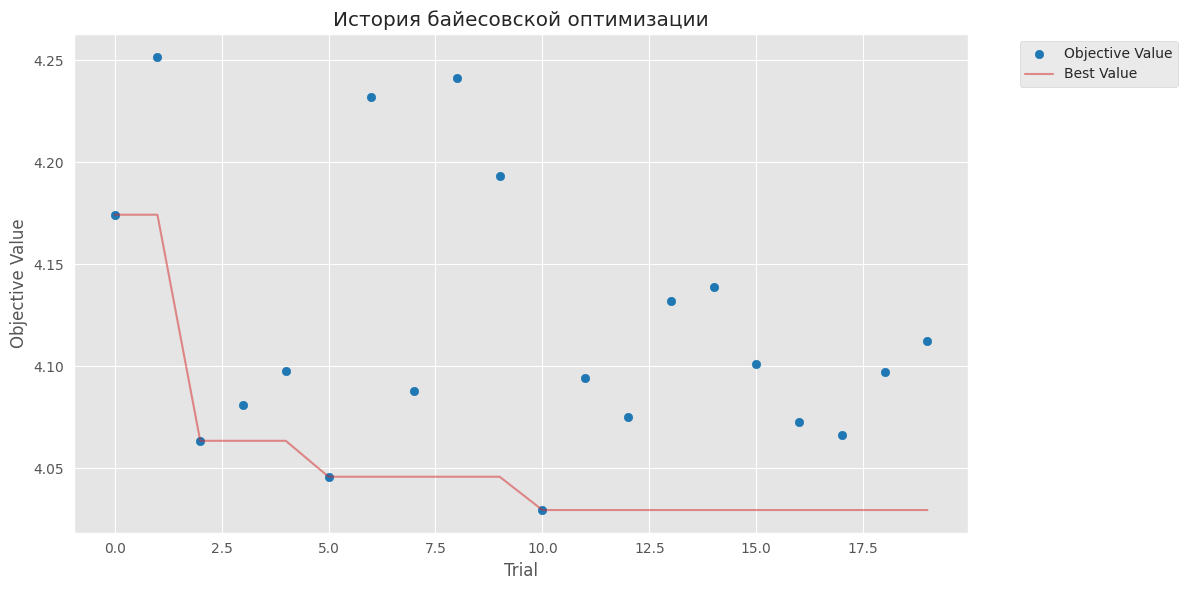

In [32]:
# История оптимизации Optuna
optuna.visualization.matplotlib.plot_optimization_history(study)
plt.title('История байесовской оптимизации')
plt.tight_layout()
plt.show()

## Шаг 26. Итоговое сравнение всех моделей на тесте

In [33]:
results = pd.DataFrame({
    'Model': ['Naive Forecast', 'Linear Regression',
              'Random Forest (tuned)', 'CatBoost (Optuna)'],
    'MAE': [m_naive[0], m_lr[0], m_rf[0], m_cb[0]],
    'RMSE': [m_naive[1], m_lr[1], m_rf[1], m_cb[1]],
    'R2': [m_naive[2], m_lr[2], m_rf[2], m_cb[2]]
}).sort_values('MAE').reset_index(drop=True)

results

,Model,MAE,RMSE,R2
0,CatBoost (Optuna),4.311836,8.699345,0.923112
1,Random Forest (tuned),4.762526,9.096374,0.915933
2,Naive Forecast,5.485604,12.369815,0.844542
3,Linear Regression,8.032322,16.249899,0.731720


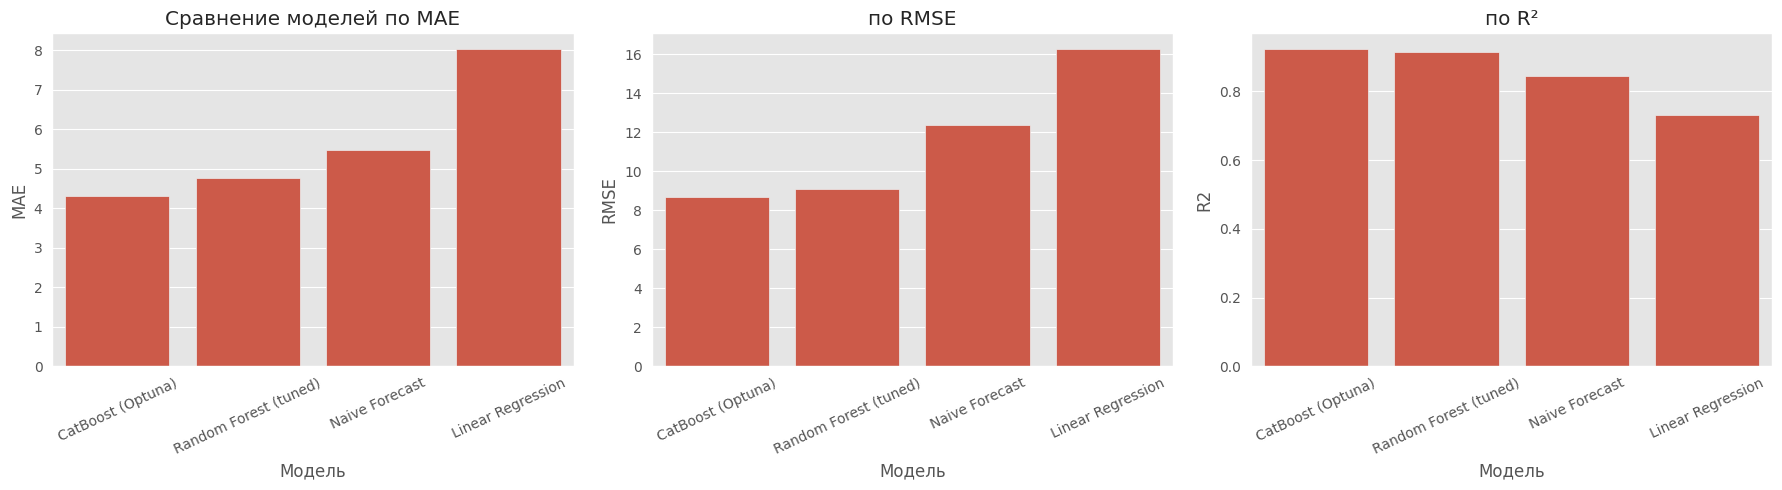

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric, title in zip(
    axes,
    ['MAE', 'RMSE', 'R2'],
    ['Сравнение моделей по MAE', 'по RMSE', 'по R²']
):
    sns.barplot(data=results, x='Model', y=metric, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Модель')
    ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

## Шаг 27. Кросс-валидация ключевых моделей: среднее и разброс

Одна цифра на тесте не показывает стабильность. Оценим лучшие модели `TimeSeriesSplit`-кросс-валидацией (3 фолда по всем данным) и представим результат как среднее ± стандартное отклонение.

In [35]:
tscv3 = TimeSeriesSplit(n_splits=3)
cv_rows = []

for name, pipe in [('Linear Regression', lr_pipe),
                   ('Random Forest (tuned)', rf_best)]:
    cv = cross_validate(
        pipe, X, y, cv=tscv3,
        scoring={'MAE': 'neg_mean_absolute_error', 'R2': 'r2'},
        n_jobs=-1
    )
    cv_rows.append({
        'Model': name,
        'MAE (mean ± std)': f"{-cv['test_MAE'].mean():.3f} ± {cv['test_MAE'].std():.3f}",
        'R2 (mean ± std)': f"{cv['test_R2'].mean():.4f} ± {cv['test_R2'].std():.4f}"
    })

# CatBoost не встраивается в sklearn-пайплайн с сырыми категориями — цикл вручную
mae_folds, r2_folds = [], []
for tr_idx, va_idx in tscv3.split(X):
    m = CatBoostRegressor(
        iterations=800, loss_function='RMSE', random_seed=SEED,
        early_stopping_rounds=80, verbose=False, **study.best_params
    )
    m.fit(X.iloc[tr_idx], y.iloc[tr_idx],
          cat_features=categorical_features,
          eval_set=(X.iloc[va_idx], y.iloc[va_idx]), verbose=False)
    pred = m.predict(X.iloc[va_idx])
    mae_folds.append(mean_absolute_error(y.iloc[va_idx], pred))
    r2_folds.append(r2_score(y.iloc[va_idx], pred))

cv_rows.append({
    'Model': 'CatBoost (Optuna)',
    'MAE (mean ± std)': f"{np.mean(mae_folds):.3f} ± {np.std(mae_folds):.3f}",
    'R2 (mean ± std)': f"{np.mean(r2_folds):.4f} ± {np.std(r2_folds):.4f}"
})

cv_summary = pd.DataFrame(cv_rows)
cv_summary

,Model,MAE (mean ± std),R2 (mean ± std)
0,Linear Regression,7.650 ± 0.733,0.8141 ± 0.0301
1,Random Forest (tuned),4.559 ± 0.342,0.9092 ± 0.0091
2,CatBoost (Optuna),4.695 ± 0.351,0.9114 ± 0.0088


**Вывод.** По кросс-валидации Random Forest и CatBoost статистически неразличимы: MAE 4.56 ± 0.34 против 4.70 ± 0.35 — разница меньше разброса по фолдам. Обе модели стабильны во времени (небольшое стандартное отклонение) и уверенно превосходят линейную регрессию (7.65 ± 0.73). На хронологическом тесте (осенне-зимний период) точнее CatBoost (MAE 4.31 против 4.76), поэтому итоговой моделью выбираем его.

## Шаг 28. Факт и прогноз лучшей модели

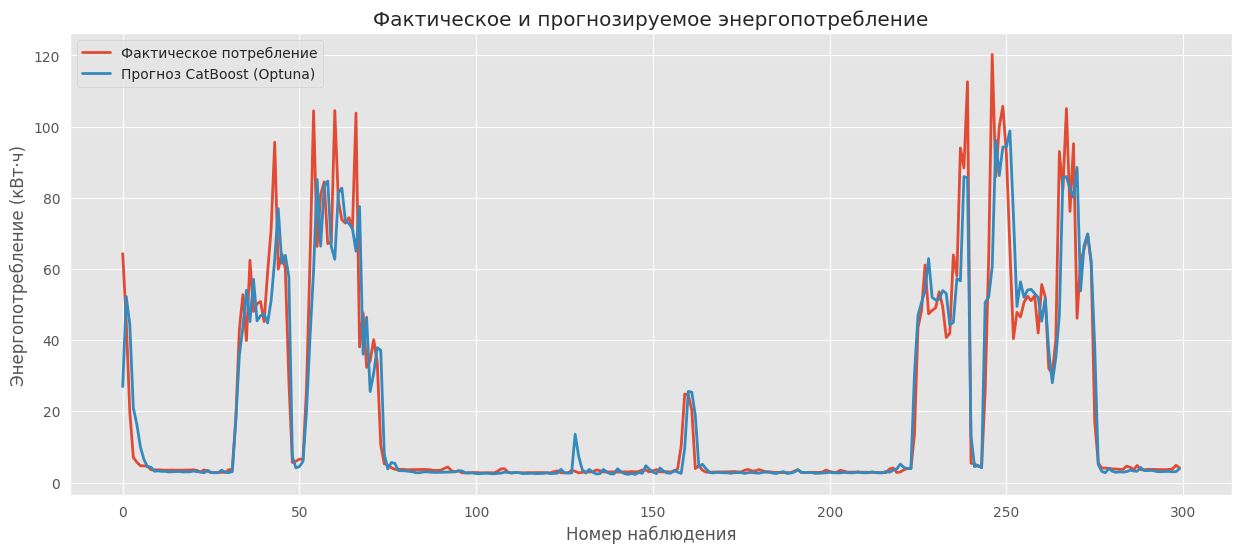

In [36]:
plt.figure(figsize=(15, 6))
plt.plot(y_test.iloc[:300].values, label='Фактическое потребление', linewidth=2)
plt.plot(y_pred_cb[:300], label='Прогноз CatBoost (Optuna)', linewidth=2)
plt.title('Фактическое и прогнозируемое энергопотребление')
plt.xlabel('Номер наблюдения')
plt.ylabel('Энергопотребление (кВт·ч)')
plt.legend()
plt.grid(True)
plt.show()

## Шаг 29. Анализ ошибок прогноза

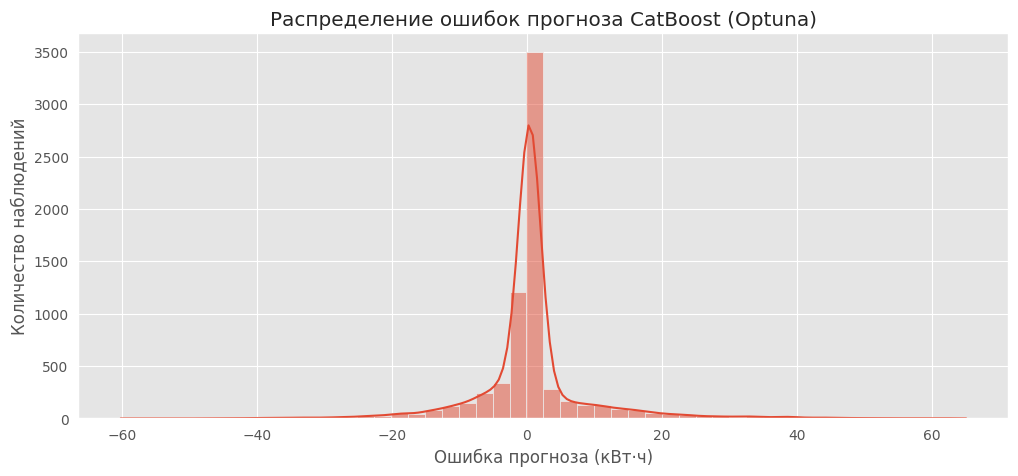

Средняя ошибка: 0.7878
Стандартное отклонение ошибок: 8.6636
Доля наблюдений с |ошибка| < MAE: 74.1%


In [37]:
errors = y_test.values - y_pred_cb

plt.figure(figsize=(12, 5))
sns.histplot(errors, bins=50, kde=True)
plt.title('Распределение ошибок прогноза CatBoost (Optuna)')
plt.xlabel('Ошибка прогноза (кВт·ч)')
plt.ylabel('Количество наблюдений')
plt.show()

print(f'Средняя ошибка: {errors.mean():.4f}')
print(f'Стандартное отклонение ошибок: {errors.std():.4f}')
print(f'Доля наблюдений с |ошибка| < MAE: {(np.abs(errors) < m_cb[0]).mean():.1%}')

**Вывод.** Ошибки распределены близко к симметричным: среднее смещение +0.79 кВт·ч невелико относительно разброса (стандартное отклонение ≈ 8.66) и означает лишь слабое систематическое занижение пиков нагрузки. У 74% наблюдений абсолютная ошибка меньше MAE. Редкие крупные ошибки приходятся на резкие скачки нагрузки, которые принципиально непредсказуемы по прошлым значениям.

## Шаг 30. Важность признаков CatBoost

                             Feature  Importance
                           Usage_kWh   26.840916
                            hour_cos   19.202823
                           CO2(tCO2)   12.179203
                     rolling_mean_1h    4.910009
                                 NSM    4.554699
                      rolling_std_1h    4.324487
                              minute    3.886261
                              lag_1h    3.664265
Lagging_Current_Reactive.Power_kVarh    2.556435
                           Load_Type    2.121876
                                hour    1.716764
                         day_of_year    1.633514
        Lagging_Current_Power_Factor    1.544631
Leading_Current_Reactive_Power_kVarh    1.528923
                               month    1.420106
                            hour_sin    1.303565
                        week_of_year    1.276516
                                 day    1.127891
                             dow_sin    0.839732
                    

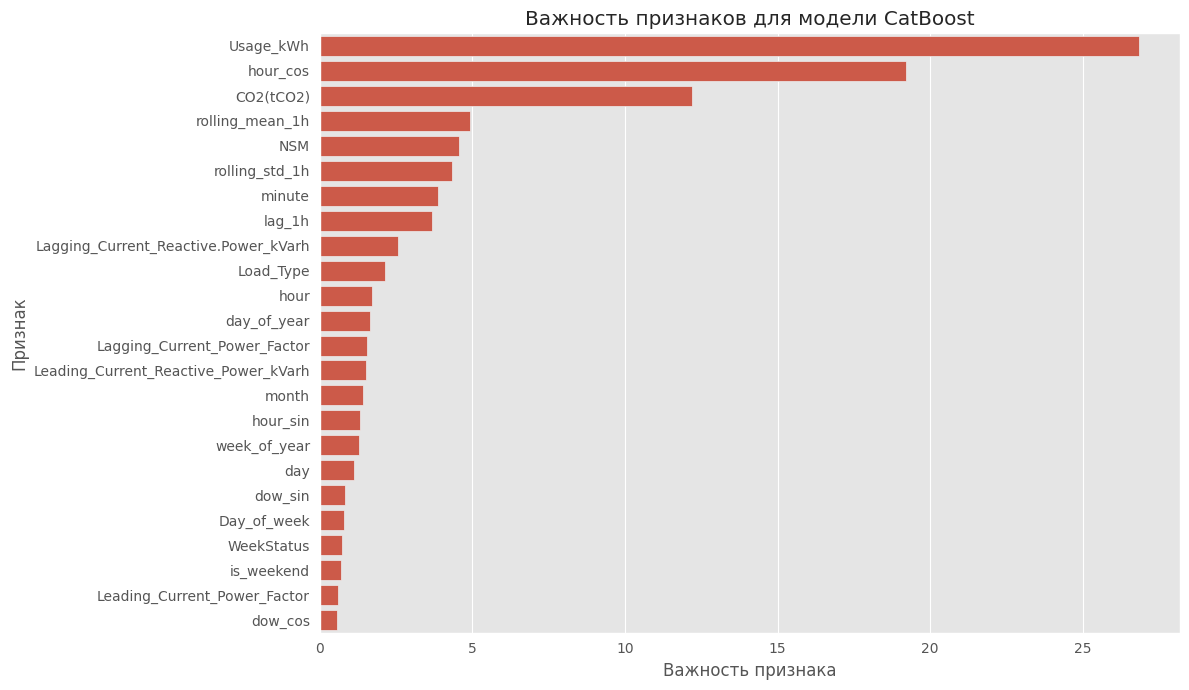

In [38]:
feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': catboost_tuned.feature_importances_
}).sort_values('Importance', ascending=False)

print(feature_importance.to_string(index=False))

plt.figure(figsize=(12, 7))
sns.barplot(data=feature_importance, x='Importance', y='Feature')
plt.title('Важность признаков для модели CatBoost')
plt.xlabel('Важность признака')
plt.ylabel('Признак')
plt.tight_layout()
plt.show()

**Вывод.** Самый важный признак — текущее потребление `Usage_kWh` (≈ 27%): ряд инерционен. Второе место занимает `hour_cos` (≈ 19%) — циклическое кодирование времени суток (гипотеза 1) оказалось одним из ключевых факторов. Созданные инерционные признаки `rolling_mean_1h`, `rolling_std_1h` и `lag_1h` суммарно дают ≈ 13% важности — гипотеза 3 подтверждена на уровне модели. Бинарный `is_weekend` и кодировки дня недели слабее (их информация частично дублируется другими признаками), но вносят ненулевой вклад.

# Итоговые выводы

В проекте построена система краткосрочного прогнозирования энергопотребления металлургического предприятия на следующий 15-минутный интервал (задача регрессии, объект — один 15-минутный интервал).

**Данные и анализ.** Набор Steel Industry Energy Consumption (~35 тыс. наблюдений за 2018 год): пропусков и дубликатов нет; распределение потребления правосторонне-асимметричное с пиковыми режимами; ряд имеет суточную и недельную сезонность — это определило хронологическую схему валидации и выбор MAE как основной метрики.

**Признаки.** Выдвинуты и проверены три гипотезы: циклическое кодирование времени, признак выходного дня и инерционные признаки (скользящие статистики, лаг). Инерционные признаки подтвердились и корреляционным анализом, и важностью в итоговой модели.

**Методология.** Хронологический holdout 80/20 + TimeSeriesSplit-кросс-валидация с отчётом «среднее ± разброс»; показано отсутствие утечек (предобработка только внутри пайплайнов, ранняя остановка и подбор параметров — без доступа к тесту). Отдельно сравнены способы масштабирования: на качество линейной регрессии они не влияют, `StandardScaler` оставлен ради интерпретируемости коэффициентов.

**Модели.** Сравнены наивный прогноз (MAE 5.49), линейная регрессия (MAE 8.03), Random Forest и CatBoost. Для Random Forest выполнен случайный поиск гиперпараметров (MAE без изменений, но RMSE 9.60 → 9.10 и R² 0.906 → 0.916), для CatBoost — байесовская оптимизация через Optuna (MAE 4.38 → 4.31, прирост 1.6%). Лучшая модель — **CatBoost после оптимизации: MAE 4.31 кВт·ч, RMSE 8.70, R² 0.923 на тесте**, что на 21% лучше наивного прогноза по MAE; по кросс-валидации модель статистически не уступает лучшей альтернативе и стабильна по фолдам.

**Дальнейшие шаги (к финальной защите):** прогноз на несколько интервалов вперёд, квантильный прогноз для оценки неопределённости, проверка устойчивости модели на другом временном периоде.